# Carga: dividir los datos y armar los `DataLoader`

Ya tenemos un `Dataset` que encuentra cada foto de Oxford Flowers 102 y su etiqueta (`00-acceso/01_un_dataset_propio`), y un pipeline de transformaciones que deja cada foto como un tensor `[3, 224, 224]` normalizado (`01-calidad/01_transforms_para_fotos`). Falta el último tramo antes de entrenar: repartir las 8.189 fotos en entrenamiento, validación y prueba, y entregárselas al modelo en lotes.

En el módulo 2 este tramo fue casi automático: MNIST ya venía separado en entrenamiento y prueba, con 6.000 imágenes por dígito y todas del mismo tamaño. Con las flores aparecen problemas que MNIST escondía:

- hay que **dividir** nosotros, y `random_split` tiene detalles (el redondeo, que los subconjuntos son vistas y no copias);
- los tres subconjuntos **comparten** el dataset de abajo, y con él el transform: el aumento de datos del entrenamiento se puede colar en la validación sin ningún aviso;
- las clases tienen entre 40 y 258 fotos, y una división al azar puede dejar a una clase con **una sola foto** en la prueba;
- los archivos vienen **agrupados por clase**, así que sin mezclar cada lote trae una o dos flores;
- leer un archivo en cada `__getitem__`, o elegir un lote demasiado grande, **frena** o **revienta** el entrenamiento.

Este notebook mide cada uno. No entrena ningún modelo; tarda alrededor de un minuto en una CPU.

**Contenido**

1. Preparación
2. El punto de partida
3. Tres conjuntos, tres trabajos
4. `random_split`: 70/15/15
5. Los subconjuntos son vistas
6. La trampa del transform compartido
7. Un transform para cada subconjunto
8. Cuántas fotos de cada clase caen en cada conjunto
9. La división oficial de Oxford
10. Mezclar o no mezclar
11. Lotes y épocas
12. Cuánto tarda una época
13. Un CSV leído en cada `__getitem__`
14. Memoria y tamaño del lote
15. Resumen y ejercicios

## 1. Preparación

Usamos `torchvision` solo para descargar los archivos la primera vez y para los nombres de las 102 clases. Todo lo demás lo leemos de los archivos crudos, en `modulo-3/data/flowers-102`, que desde este notebook es `../data/flowers-102`.

In [1]:
import csv
import math
import os
import time

import scipy.io
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from torchvision import datasets, transforms
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"                                   # modulo-3/data
CARPETA = os.path.join(RAIZ, "flowers-102")

# torchvision descarga los archivos (solo la primera vez) y trae los nombres de las clases
NOMBRES = datasets.Flowers102(root=RAIZ, split="train", download=True).classes
print("clases:", len(NOMBRES), "  las tres primeras:", NOMBRES[:3])

Versión de PyTorch: 2.11.0+cpu
clases: 102   las tres primeras: ['pink primrose', 'hard-leaved pocket orchid', 'canterbury bells']


## 2. El punto de partida

El `Dataset` de `00-acceso/01_un_dataset_propio`, en versión corta: en `__init__` lee las etiquetas del `.mat` y les resta 1 para que vayan de 0 a 101; en `__getitem__` abre la foto `idx + 1`, porque los archivos parten en `image_00001.jpg`. Guarda las etiquetas como enteros de Python, así que los lotes de etiquetas salen `int64`, como en MNIST.

El transform es el de `01-calidad/01_transforms_para_fotos`: `Resize(256)` lleva el lado corto a 256 píxeles sin deformar, `CenterCrop(224)` recorta el cuadrado del centro, `ToTensor` lo pasa a tensor entre 0 y 1, y `Normalize` lo centra con la media y la desviación de ImageNet, como en el curso. Es la misma receta con la que torchvision prepara las fotos para sus modelos entrenados en ImageNet, por ejemplo [ResNet-18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html): lado corto a 256, recorte central de 224 y esos seis números. Como no tiene nada aleatorio, la llamamos `transform_evaluacion`: es la que se usa para validar y probar.

In [2]:
class FloresOxford(Dataset):
    """Las 8.189 fotos de Oxford Flowers 102, cargadas a pedido."""

    def __init__(self, carpeta, transform=None):
        self.carpeta_imagenes = os.path.join(carpeta, "jpg")
        self.transform = transform
        etiquetas = scipy.io.loadmat(os.path.join(carpeta, "imagelabels.mat"))["labels"][0]
        self.etiquetas = [int(e) - 1 for e in etiquetas]          # 1..102  ->  0..101

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, idx):
        ruta = os.path.join(self.carpeta_imagenes, f"image_{idx + 1:05d}.jpg")   # los archivos parten en 1
        with Image.open(ruta) as archivo:
            imagen = archivo.convert("RGB")
        if self.transform is not None:
            imagen = self.transform(imagen)
        return imagen, self.etiquetas[idx]


MEDIA_IMAGENET = [0.485, 0.456, 0.406]
DESVIACION_IMAGENET = [0.229, 0.224, 0.225]

transform_evaluacion = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, DESVIACION_IMAGENET),
])

flores = FloresOxford(CARPETA, transform=transform_evaluacion)
imagen, etiqueta = flores[0]
print(f"{len(flores)} fotos; la primera: forma {tuple(imagen.shape)}, etiqueta {etiqueta} ({NOMBRES[etiqueta]})")

8189 fotos; la primera: forma (3, 224, 224), etiqueta 76 (passion flower)


Para mirar las fotos hace falta deshacer la normalización: multiplicar por la desviación, sumar la media y pasar los canales al final, que es como los espera `matplotlib`.

In [3]:
def para_mostrar(x):
    """Deshace Normalize y deja la imagen como [alto, ancho, canales] entre 0 y 1."""
    media = torch.tensor(MEDIA_IMAGENET).view(3, 1, 1)
    desviacion = torch.tensor(DESVIACION_IMAGENET).view(3, 1, 1)
    return (x * desviacion + media).clamp(0, 1).permute(1, 2, 0)

## 3. Tres conjuntos, tres trabajos

Cada conjunto responde una pregunta distinta:

- **Entrenamiento**: los ejemplos de los que el modelo aprende. Es el único que ve el optimizador.
- **Validación**: para decidir mientras se trabaja. Con ella se comparan modelos y transforms, se elige la tasa de aprendizaje o la mejor época.
- **Prueba**: para informar, al final y **una sola vez**, cuánto acierta el modelo con fotos que no influyeron en ninguna decisión.

Es la misma separación del proyecto de punta a punta del módulo 1 (`05-profundizacion/06_proyecto_de_punta_a_punta`, sección 5) y de MNIST en el módulo 2 (`04-clasificacion-de-imagenes/01_mnist_de_punta_a_punta`, sección 3).

La guía de validación cruzada de scikit-learn explica [por qué hacen falta tres y no dos](https://scikit-learn.org/stable/modules/cross_validation.html). Evaluar en los mismos datos con que se entrenó es un error de método: un modelo que repitiera las etiquetas que vio tendría un puntaje perfecto. Por eso se aparta una prueba. Pero si después se ajustan los hiperparámetros mirando la prueba, el conocimiento sobre ella "se filtra" al modelo y la cifra final deja de medir lo que el modelo hace con datos nuevos. La solución es apartar un tercer conjunto, la validación, para decidir. La misma guía advierte el costo: con tres conjuntos quedan menos ejemplos para aprender, y el resultado depende de qué fotos cayeron en cada uno. Las dos cosas se ven en las secciones 8 y 9.

## 4. `random_split`: 70/15/15

El curso usa 70% para entrenar, 15% para validar y 15% para probar. `random_split(dataset, tamaños)` mezcla los índices al azar y los corta en trozos de los tamaños pedidos. Los tamaños se calculan con `int`, que trunca, y la prueba se queda con el resto:

In [4]:
n = len(flores)
n_entrenamiento = int(0.7 * n)
n_validacion = int(0.15 * n)
n_prueba = n - n_entrenamiento - n_validacion       # el resto: así la suma da n siempre

print(f"0.70 × {n} = {0.70 * n:8.2f}  ->  entrenamiento {n_entrenamiento}")
print(f"0.15 × {n} = {0.15 * n:8.2f}  ->  validación    {n_validacion}")
print(f"el resto               ->  prueba        {n_prueba}")

entrenamiento, validacion, prueba = random_split(
    flores, [n_entrenamiento, n_validacion, n_prueba], generator=torch.Generator().manual_seed(0)
)
print("\ntamaños:", len(entrenamiento), len(validacion), len(prueba))

0.70 × 8189 =  5732.30  ->  entrenamiento 5732
0.15 × 8189 =  1228.35  ->  validación    1228
el resto               ->  prueba        1229

tamaños: 5732 1228 1229


Al truncar, 0.70 × 8.189 = 5732.3 queda en 5.732 y 0.15 × 8.189 = 1228.35 queda en 1.228. Las 1.229 fotos restantes van a la prueba. Si la prueba también se calculara con `int(0.15 * n)`, la suma daría 8.188, una foto menos que el dataset, y `random_split` no lo acepta:

In [5]:
try:
    random_split(flores, [n_entrenamiento, n_validacion, int(0.15 * n)])
except ValueError as error:
    print("ValueError:", error)

ValueError: Sum of input lengths does not equal the length of the input dataset!


`random_split` también acepta fracciones. Su documentación dice qué hace con el resto: calcula cada tamaño como `floor(frac * len(dataset))` y, si sobran ejemplos, los reparte de a uno, por turnos, empezando por el primer subconjunto ([`torch.utils.data.random_split`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.random_split)). Con 8.189 fotos los pisos suman 8.188, así que sobra una, y le toca al entrenamiento:

In [6]:
e_frac, v_frac, p_frac = random_split(flores, [0.7, 0.15, 0.15], generator=torch.Generator().manual_seed(0))
print("con fracciones:", len(e_frac), len(v_frac), len(p_frac))
print("con enteros   :", len(entrenamiento), len(validacion), len(prueba))

print("\n¿El entrenamiento con fracciones contiene al de enteros?",
      set(entrenamiento.indices) <= set(e_frac.indices))
print("fotos de validación que cambian de una versión a la otra:",
      len(set(validacion.indices) - set(v_frac.indices)))

con fracciones: 5733 1228 1228
con enteros   : 5732 1228 1229

¿El entrenamiento con fracciones contiene al de enteros? True
fotos de validación que cambian de una versión a la otra: 1


Las dos versiones son correctas y casi iguales: con la misma semilla, `random_split` sortea la misma permutación de los 8.189 índices y solo corre los cortes un lugar: la primera foto de la validación pasa al entrenamiento y la primera de la prueba pasa a la validación. La lección práctica es otra: **la división se fija una vez y se guarda**. Si en un experimento se usa una y en el siguiente la otra, una foto que estaba en la prueba ahora está en la validación, y las cifras dejan de ser comparables. Fijar la semilla del generador, como aquí, y guardar los índices (ejercicio 4) evita ese problema.

## 5. Los subconjuntos son vistas

`random_split` no copia ninguna foto. Devuelve tres objetos `Subset`, que según su documentación son un "subconjunto de un dataset en los índices indicados" ([`torch.utils.data.Subset`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.Subset)). Cada uno guarda dos cosas: el dataset completo, en `.dataset`, y la lista de índices que le tocaron, en `.indices`:

In [7]:
print("tipo:", type(entrenamiento).__name__)
print("primeros índices de entrenamiento:", entrenamiento.indices[:6])
print("¿Los tres apuntan al mismo dataset?",
      entrenamiento.dataset is flores, validacion.dataset is flores, prueba.dataset is flores)

x_vista, y_vista = entrenamiento[0]
x_original, y_original = flores[entrenamiento.indices[0]]
print(f"\n¿entrenamiento[0] es flores[{entrenamiento.indices[0]}]?",
      torch.equal(x_vista, x_original) and y_vista == y_original)

e, v, p = set(entrenamiento.indices), set(validacion.indices), set(prueba.indices)
print("índices en común: entrenamiento-validación", len(e & v), "  entrenamiento-prueba", len(e & p),
      "  validación-prueba", len(v & p))
print("entre los tres cubren", len(e | v | p), "de", n, "fotos")

tipo: Subset
primeros índices de entrenamiento: [6095, 1316, 1657, 6831, 7132, 2384]
¿Los tres apuntan al mismo dataset? True True True



¿entrenamiento[0] es flores[6095]? True
índices en común: entrenamiento-validación 0   entrenamiento-prueba 0   validación-prueba 0
entre los tres cubren 8189 de 8189 fotos


`entrenamiento[0]` no es la foto 0 sino la foto 6095 del dataset: el `Subset` traduce su índice local al índice del dataset de abajo y le pide esa foto. Los tres subconjuntos no comparten ningún índice y entre los tres cubren las 8.189 fotos, que es lo que la documentación de `random_split` promete con "non-overlapping".

Que sean vistas tiene una ventaja y un peligro. La ventaja: dividir no cuesta memoria, son tres listas de enteros. El peligro es la sección siguiente.

## 6. La trampa del transform compartido

El entrenamiento suele llevar **aumento de datos**: transformaciones aleatorias que muestran una versión distinta de cada foto en cada época (se estudian en `03-robustez/01_pipelines_a_prueba_de_fallas`). Una versión mínima: `RandomResizedCrop(224)` recorta una zona al azar y la lleva a 224 × 224, y `RandomHorizontalFlip()` refleja la foto la mitad de las veces.

In [8]:
transform_entrenamiento = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, DESVIACION_IMAGENET),
])

¿Cómo se le da este transform solo al entrenamiento? El primer intento natural es asignárselo al subconjunto. Python lo acepta sin quejarse, porque a un `Subset`, como a casi cualquier objeto de Python, se le puede agregar un atributo nuevo. Para saber si se aplica, pedimos la misma foto dos veces: con un transform aleatorio deberían salir distintas.

In [9]:
entrenamiento.transform = transform_entrenamiento       # intento 1: ningún error...

a, _ = entrenamiento[0]
b, _ = entrenamiento[0]
print("¿entrenamiento[0] cambia de un acceso a otro?", not torch.equal(a, b))
print("¿qué transform se usa en realidad?",
      "el de evaluación" if entrenamiento.dataset.transform is transform_evaluacion else "otro")

¿entrenamiento[0] cambia de un acceso a otro? False
¿qué transform se usa en realidad? el de evaluación


No se aplica. `Subset.__getitem__` le pide la foto al dataset de abajo, y ese dataset usa su propio `self.transform`; el atributo que agregamos al `Subset` no lo lee nadie. Es un error silencioso: se entrena sin aumento de datos creyendo que lo hay.

El segundo intento corrige eso y cambia el transform del dataset de abajo:

In [10]:
del entrenamiento.transform
entrenamiento.dataset.transform = transform_entrenamiento     # intento 2

a, _ = entrenamiento[0]
b, _ = entrenamiento[0]
print("¿entrenamiento[0] cambia de un acceso a otro?", not torch.equal(a, b))

v1, _ = validacion[0]
v2, _ = validacion[0]
p1, _ = prueba[0]
p2, _ = prueba[0]
print("¿validacion[0] cambia de un acceso a otro?   ", not torch.equal(v1, v2))
print("¿prueba[0] cambia de un acceso a otro?       ", not torch.equal(p1, p2))

¿entrenamiento[0] cambia de un acceso a otro? True


¿validacion[0] cambia de un acceso a otro?    True
¿prueba[0] cambia de un acceso a otro?        True


Ahora el entrenamiento sí cambia en cada acceso, pero la validación y la prueba también: los tres `Subset` apuntan al mismo `flores`, y le cambiamos el transform a los tres a la vez. Así se ve la primera foto de validación pedida cuatro veces, al lado de la versión que debería salir siempre:

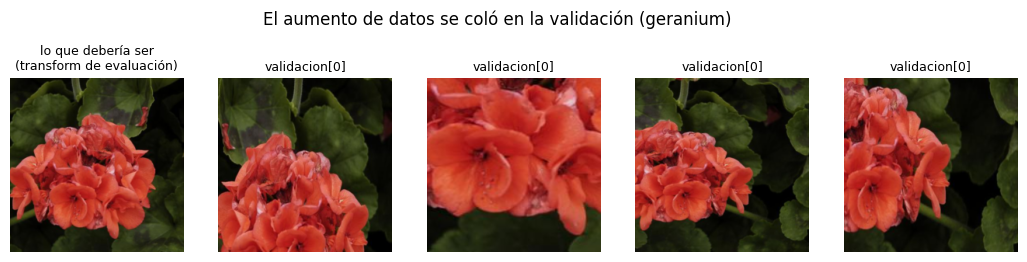

In [11]:
fig, ejes = plt.subplots(1, 5, figsize=(13, 2.9))
indice_original = validacion.indices[0]
ejes[0].imshow(para_mostrar(transform_evaluacion(FloresOxford(CARPETA)[indice_original][0])))
ejes[0].set_title("lo que debería ser\n(transform de evaluación)", fontsize=9)
for eje in ejes[1:]:
    x, _ = validacion[0]
    eje.imshow(para_mostrar(x))
    eje.set_title("validacion[0]", fontsize=9)
for eje in ejes:
    eje.axis("off")
plt.suptitle(f"El aumento de datos se coló en la validación ({NOMBRES[validacion[0][1]]})", y=1.03)
plt.show()

flores.transform = transform_evaluacion        # dejamos todo como estaba

La validación ya no mide siempre lo mismo. Cada época vería recortes distintos de las mismas fotos, algunos con la flor cortada, y la exactitud de validación subiría y bajaría por el sorteo de los recortes y no solo por el modelo. Comparar dos épocas, o dos modelos, deja de tener sentido. Lo peor es que nada avisa: el código corre y los números se ven razonables.

## 7. Un transform para cada subconjunto

Hay dos formas correctas. La **primera** divide un dataset **sin** transform, que entrega imágenes PIL, y envuelve cada subconjunto en un dataset mínimo que aplica el transform que le corresponde:

In [12]:
class ConTransform(Dataset):
    """Aplica un transform propio a las muestras de otro dataset, por ejemplo un Subset."""

    def __init__(self, base, transform):
        self.base = base
        self.transform = transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        imagen, etiqueta = self.base[i]
        return self.transform(imagen), etiqueta


flores_pil = FloresOxford(CARPETA)                        # sin transform: entrega imágenes PIL
e_pil, v_pil, p_pil = random_split(
    flores_pil, [n_entrenamiento, n_validacion, n_prueba], generator=torch.Generator().manual_seed(0)
)
entrenamiento_1 = ConTransform(e_pil, transform_entrenamiento)
validacion_1 = ConTransform(v_pil, transform_evaluacion)
prueba_1 = ConTransform(p_pil, transform_evaluacion)
print("tipo de flores_pil[0][0]:", type(flores_pil[0][0]).__name__)
print("¿mismos índices que antes?", e_pil.indices == entrenamiento.indices and v_pil.indices == validacion.indices)

tipo de flores_pil[0][0]: Image
¿mismos índices que antes? True


La **segunda** crea un dataset de base por cada transform y arma los `Subset` a mano con los mismos índices. No cuesta memoria extra: cada `FloresOxford` guarda solo la lista de etiquetas, no las fotos.

In [13]:
entrenamiento_2 = Subset(FloresOxford(CARPETA, transform_entrenamiento), entrenamiento.indices)
validacion_2 = Subset(FloresOxford(CARPETA, transform_evaluacion), validacion.indices)
prueba_2 = Subset(FloresOxford(CARPETA, transform_evaluacion), prueba.indices)

Comprobamos que las dos hacen lo que deben: el entrenamiento cambia en cada acceso, la validación no, y la validación coincide con aplicar a mano el transform de evaluación a la foto original.

In [14]:
for nombre, ent, val in [("forma 1, ConTransform", entrenamiento_1, validacion_1),
                         ("forma 2, un dataset por transform", entrenamiento_2, validacion_2)]:
    a, _ = ent[0]
    b, _ = ent[0]
    v1, _ = val[0]
    v2, _ = val[0]
    print(f"{nombre}:")
    print(f"   entrenamiento cambia: {not torch.equal(a, b)}   validación cambia: {not torch.equal(v1, v2)}")

esperada = transform_evaluacion(flores_pil[validacion.indices[0]][0])
print("\n¿La validación es el transform de evaluación aplicado a la foto original?",
      torch.equal(validacion_1[0][0], esperada) and torch.equal(validacion_2[0][0], esperada))

forma 1, ConTransform:
   entrenamiento cambia: True   validación cambia: False
forma 2, un dataset por transform:
   entrenamiento cambia: True   validación cambia: False

¿La validación es el transform de evaluación aplicado a la foto original? True


Las dos funcionan. La primera es cómoda cuando se divide con `random_split` en el mismo notebook. La segunda sirve cuando los índices vienen de otro lado, por ejemplo de un archivo guardado o de la división oficial de la sección 9. En las dos, el transform de cada subconjunto vive en un objeto propio y cambiar uno no toca a los demás.

Una advertencia de la documentación de `Subset`: si en vez de envolverlo se hace una subclase de `Subset` que redefine `__getitem__`, también hay que redefinir `__getitems__`, o PyTorch lanza `NotImplementedError` ([nota de `Subset`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.Subset)). La documentación dice que el error aparece al usar el `DataLoader`; en la versión que usamos aparece antes, al crear el objeto:

In [15]:
class SubsetConTransform(Subset):
    """La tentación: heredar de Subset y redefinir solo __getitem__."""

    def __init__(self, base, indices, transform):
        super().__init__(base, indices)
        self.transform = transform

    def __getitem__(self, i):
        imagen, etiqueta = super().__getitem__(i)
        return self.transform(imagen), etiqueta


try:
    SubsetConTransform(flores_pil, validacion.indices, transform_evaluacion)
except NotImplementedError as error:
    print("NotImplementedError:", str(error).splitlines()[0])

NotImplementedError: SubsetConTransform overrides __getitem__ but not __getitems__. When subclassing Subset and overriding __getitem__, you must also override __getitems__ to ensure DataLoader works correctly with your custom logic. A simple implementation:


Con un envoltorio aparte, como `ConTransform`, ese problema no existe.

## 8. Cuántas fotos de cada clase caen en cada conjunto

`random_split` sortea fotos, no clases. Con 102 clases de tamaños muy distintos, ¿cuántas fotos de cada una caen en cada conjunto? Solo hacen falta las etiquetas, no las fotos:

In [16]:
etiquetas = torch.tensor(flores.etiquetas)
por_clase = torch.bincount(etiquetas, minlength=102)
print(f"fotos por clase en el dataset: entre {por_clase.min()} y {por_clase.max()}\n")


def resumen_por_clase(nombre, indices):
    cuenta = torch.bincount(etiquetas[indices], minlength=102)
    fraccion = cuenta / por_clase
    print(f"{nombre:14s} {len(indices):5d} fotos   por clase: entre {cuenta.min():3d} y {cuenta.max():3d}   "
          f"fracción de su clase: entre {fraccion.min():4.0%} y {fraccion.max():4.0%}   "
          f"clases con 3 fotos o menos: {(cuenta <= 3).sum()}")
    return cuenta


cuentas_azar = {nombre: resumen_por_clase(nombre, sub.indices)
                for nombre, sub in [("entrenamiento", entrenamiento), ("validación", validacion), ("prueba", prueba)]}

fotos por clase en el dataset: entre 40 y 258

entrenamiento   5732 fotos   por clase: entre  27 y 170   fracción de su clase: entre  59% y  83%   clases con 3 fotos o menos: 0
validación      1228 fotos   por clase: entre   2 y  46   fracción de su clase: entre   5% y  29%   clases con 3 fotos o menos: 5
prueba          1229 fotos   por clase: entre   1 y  45   fracción de su clase: entre   2% y  27%   clases con 3 fotos o menos: 2


Ninguna clase quedó fuera, pero el reparto es muy desparejo. Lo esperado es que cada conjunto se lleve el 15% de cada clase, y hay clases con apenas el 2% de sus fotos en la prueba y otras con el 27%. Las peores:

In [17]:
for nombre in ["validación", "prueba"]:
    cuenta = cuentas_azar[nombre]
    peor = int(cuenta.argmin())
    print(f"{nombre:10s}: la clase {peor} ({NOMBRES[peor]}) tiene {por_clase[peor]} fotos y solo {cuenta[peor]} "
          f"en este conjunto; esperábamos unas {0.15 * por_clase[peor]:.0f}")

validación: la clase 25 (corn poppy) tiene 41 fotos y solo 2 en este conjunto; esperábamos unas 6
prueba    : la clase 92 (ball moss) tiene 46 fotos y solo 1 en este conjunto; esperábamos unas 7


Con una sola foto de prueba, la exactitud de esa clase solo puede valer 0% o 100%: no mide nada. Es el problema que describe la guía de scikit-learn en su sección sobre [estratificación](https://scikit-learn.org/stable/modules/cross_validation.html#stratification): con clases poco frecuentes, una división al azar puede dejar un conjunto sin ningún ejemplo de una clase, y por eso hay divisores que hacen un **muestreo estratificado**, para que la proporción de cada clase se conserve aproximadamente en cada parte.

Estratificar a mano es sencillo: se divide cada clase por separado, 70/15/15, y se juntan los pedazos.

In [18]:
def division_estratificada(etiquetas, fracciones=(0.70, 0.15, 0.15), semilla=0):
    """Divide cada clase por separado y junta los pedazos. Devuelve tres listas de índices."""
    generador = torch.Generator().manual_seed(semilla)
    partes = ([], [], [])
    for clase in range(int(etiquetas.max()) + 1):
        indices = torch.nonzero(etiquetas == clase).flatten()
        indices = indices[torch.randperm(len(indices), generator=generador)]
        n_val = round(fracciones[1] * len(indices))
        n_pru = round(fracciones[2] * len(indices))
        n_ent = len(indices) - n_val - n_pru
        partes[0].extend(indices[:n_ent].tolist())
        partes[1].extend(indices[n_ent:n_ent + n_val].tolist())
        partes[2].extend(indices[n_ent + n_val:].tolist())
    return partes


estratificada = division_estratificada(etiquetas)
cuentas_estratificadas = {nombre: resumen_por_clase(nombre, indices)
                          for nombre, indices in zip(["entrenamiento", "validación", "prueba"], estratificada)}

entrenamiento   5737 fotos   por clase: entre  28 y 180   fracción de su clase: entre  68% y  72%   clases con 3 fotos o menos: 0
validación      1226 fotos   por clase: entre   6 y  39   fracción de su clase: entre  14% y  16%   clases con 3 fotos o menos: 0
prueba          1226 fotos   por clase: entre   6 y  39   fracción de su clase: entre  14% y  16%   clases con 3 fotos o menos: 0


Los totales cambian un poco por el redondeo (5.737, 1.226 y 1.226), pero ahora cada clase tiene entre 6 y 39 fotos en la validación y en la prueba, y la fracción va del 14% al 16%: lo que sobra es solo el redondeo. El gráfico muestra la fracción de cada clase que cayó en la prueba, según cuántas fotos tiene la clase:

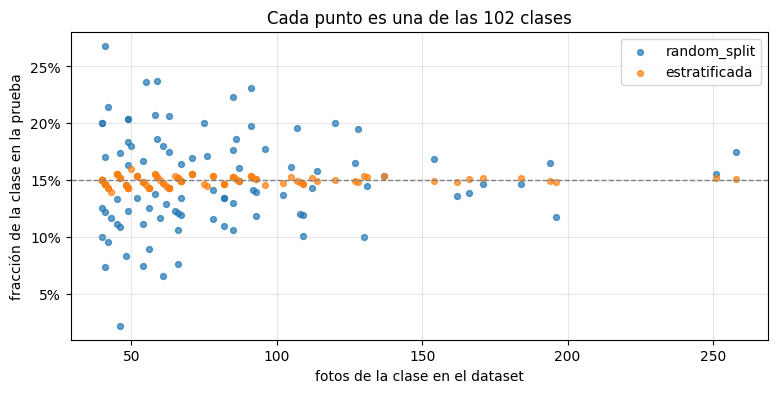

In [19]:
fig, eje = plt.subplots(figsize=(9, 4))
eje.scatter(por_clase, cuentas_azar["prueba"] / por_clase, s=18, alpha=0.7, label="random_split")
eje.scatter(por_clase, cuentas_estratificadas["prueba"] / por_clase, s=18, alpha=0.7, label="estratificada")
eje.axhline(0.15, color="gray", linestyle="--", linewidth=1)
eje.set_xlabel("fotos de la clase en el dataset")
eje.set_ylabel("fracción de la clase en la prueba")
eje.set_title("Cada punto es una de las 102 clases")
eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
eje.grid(alpha=0.3)
eje.legend()
plt.show()

Con `random_split` la dispersión es mayor en las clases chicas, a la izquierda: con 40 fotos, que caigan 1 o 11 en la prueba cambia mucho la fracción, y con 200 el azar se promedia. La división estratificada deja todas las clases en la línea del 15%.

Un detalle que importa después: `division_estratificada` junta los índices **clase por clase**. La lista de entrenamiento empieza con todas las fotos de la clase 0, sigue con las de la clase 1, y así. La sección 10 muestra por qué eso obliga a mezclar.

## 9. La división oficial de Oxford

El dataset trae su propia división en `setid.mat`, con tres listas de números de foto: `trnid`, `valid` y `tstid`. Los números parten en 1, como los nombres de archivo, así que también hay que restarles 1:

In [20]:
division = scipy.io.loadmat(os.path.join(CARPETA, "setid.mat"))
oficial = {nombre: [int(i) - 1 for i in division[clave][0]]
           for nombre, clave in [("entrenamiento", "trnid"), ("validación", "valid"), ("prueba", "tstid")]}

for nombre, indices in oficial.items():
    print(f"{len(indices) / n:5.1%}  ", end="")
    resumen_por_clase(nombre, indices)

conjuntos = [set(indices) for indices in oficial.values()]
print("\n¿Se tocan?", any(a & b for a, b in [(conjuntos[0], conjuntos[1]), (conjuntos[0], conjuntos[2]), (conjuntos[1], conjuntos[2])]),
      "  ¿Cubren las", n, "fotos?", len(set().union(*conjuntos)) == n)

12.5%  entrenamiento   1020 fotos   por clase: entre  10 y  10   fracción de su clase: entre   4% y  25%   clases con 3 fotos o menos: 0
12.5%  validación      1020 fotos   por clase: entre  10 y  10   fracción de su clase: entre   4% y  25%   clases con 3 fotos o menos: 0
75.1%  prueba          6149 fotos   por clase: entre  20 y 238   fracción de su clase: entre  50% y  92%   clases con 3 fotos o menos: 0

¿Se tocan? False   ¿Cubren las 8189 fotos? True


Es casi la división al revés: 12.5% para entrenar, 12.5% para validar y 75% para probar. Exactamente 10 fotos por clase en el entrenamiento y 10 en la validación, y el resto, entre 20 y 238 por clase, en la prueba.

El artículo que presentó el dataset explica el diseño ([Nilsback y Zisserman, 2008](https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/nilsback08.pdf), sección 4): el entrenamiento y la validación tienen 10 fotos por clase cada uno, y la prueba se queda con todo lo demás, con un mínimo de 20 por clase. La validación sirvió para ajustar los parámetros de su método, y el desempeño se mide **por clase** y se promedia sobre las clases, no sobre las fotos. El artículo da 1.030 fotos de entrenamiento y 6.129 de prueba porque entonces había 103 clases; según el [README del dataset](https://thor.robots.ox.ac.uk/flowers/102/README.txt), las dos clases de petunias se unieron después porque eran la misma flor. Con 102 clases salen las 1.020 y 6.149 de la salida.

¿Por qué una división tan distinta de la del curso? Porque responden preguntas distintas:

- La oficial está hecha para **comparar métodos**: todos aprenden de las mismas pocas fotos por clase, un problema difícil, y se evalúan con una prueba grande donde cada clase tiene al menos 20 fotos. En el artículo, la validación sirve para elegir los parámetros, y después el modelo final se vuelve a entrenar con el entrenamiento y la validación juntos (sección 4.1), es decir, con 20 fotos por clase. Si se quiere comparar un resultado con uno publicado sobre Flowers 102, hay que usar esta división.
- La del curso está hecha para **entrenar el mejor modelo posible** con los datos disponibles: le da al modelo el 70% de las fotos.

Mezclar las dos cosas es un error común: entrenar con 70/15/15 y comparar la cifra con artículos que entrenaron con 20 fotos por clase. Y hay una segunda diferencia: la cifra del artículo es la exactitud **promediada por clase**, donde cada clase pesa lo mismo, mientras que la exactitud habitual promedia sobre las fotos, y en ella las clases grandes pesan más. Con clases de 40 a 258 fotos, las dos pueden dar números distintos.

## 10. Mezclar o no mezclar

`DataLoader` tiene el parámetro `shuffle`: según su documentación, con `True` los datos "se vuelven a mezclar en cada época", y por defecto vale `False` ([`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader)). En el módulo 2 vimos qué pasa al entrenar con los datos ordenados por clase: el modelo aprende la clase de turno y olvida las anteriores (`04-clasificacion-de-imagenes/02_experimentos_con_mnist`, sección 2). Aquí solo miramos qué llega en cada lote.

Para no cargar miles de fotos solo para mirar etiquetas, usamos un dataset que entrega únicamente la etiqueta. El `DataLoader` le pide los índices en el mismo orden en que se los pediría a `FloresOxford`.

In [21]:
class SoloEtiquetas(Dataset):
    def __len__(self):
        return len(etiquetas)

    def __getitem__(self, idx):
        return int(etiquetas[idx])


solo_etiquetas = SoloEtiquetas()
casos = {
    "todas, en el orden de los archivos": (solo_etiquetas, False),
    "oficial (trnid), sin mezclar": (Subset(solo_etiquetas, oficial["entrenamiento"]), False),
    "estratificada, sin mezclar": (Subset(solo_etiquetas, estratificada[0]), False),
    "random_split, sin mezclar": (Subset(solo_etiquetas, entrenamiento.indices), False),
    "random_split, shuffle=True": (Subset(solo_etiquetas, entrenamiento.indices), True),
}

torch.manual_seed(0)
for nombre, (datos, mezclar) in casos.items():
    cargador = DataLoader(datos, batch_size=32, shuffle=mezclar)
    distintas = [len(set(lote.tolist())) for lote in cargador if len(lote) == 32]    # solo lotes completos
    primero_1 = next(iter(cargador))[:6].tolist()
    primero_2 = next(iter(cargador))[:6].tolist()
    print(f"{nombre:36s} clases distintas por lote de 32: {sum(distintas) / len(distintas):4.1f} en promedio   "
          f"primer lote, dos épocas: {primero_1} {primero_2}")

cuenta_ent = torch.bincount(etiquetas[entrenamiento.indices], minlength=102).double()
total_ent = torch.tensor(float(len(entrenamiento)), dtype=torch.float64)
con_reposicion = (1 - (1 - cuenta_ent / total_ent) ** 32).sum()


def log_combinaciones(a, b):
    """log del número de formas de elegir b elementos entre a."""
    return torch.lgamma(a + 1) - torch.lgamma(b + 1) - torch.lgamma(a - b + 1)


k = torch.tensor(32.0, dtype=torch.float64)
ausente = torch.exp(log_combinaciones(total_ent - cuenta_ent, k) - log_combinaciones(total_ent, k))
sin_reposicion = (1 - ausente).sum()
print(f"\nclases distintas esperadas en 32 fotos al azar: {con_reposicion:.2f} con reposición, "
      f"{sin_reposicion:.2f} sin reposición")

todas, en el orden de los archivos   clases distintas por lote de 32:  1.5 en promedio   primer lote, dos épocas: [76, 76, 76, 76, 76, 76] [76, 76, 76, 76, 76, 76]
oficial (trnid), sin mezclar         clases distintas por lote de 32:  4.0 en promedio   primer lote, dos épocas: [0, 0, 0, 0, 0, 0] [0, 0, 0, 0, 0, 0]
estratificada, sin mezclar           clases distintas por lote de 32:  1.6 en promedio   primer lote, dos épocas: [0, 0, 0, 0, 0, 0] [0, 0, 0, 0, 0, 0]


random_split, sin mezclar            clases distintas por lote de 32: 26.8 en promedio   primer lote, dos épocas: [13, 50, 81, 23, 44, 42] [13, 50, 81, 23, 44, 42]
random_split, shuffle=True           clases distintas por lote de 32: 26.7 en promedio   primer lote, dos épocas: [16, 54, 85, 34, 14, 50] [77, 71, 68, 42, 72, 100]

clases distintas esperadas en 32 fotos al azar: 26.64 con reposición, 26.70 sin reposición


En el orden de los archivos, un lote de 32 trae 1.5 clases en promedio: las fotos están guardadas por clase. La división oficial viene agrupada por clase, con las 10 fotos de cada una seguidas, así que cada lote trae 4 flores. La estratificada, armada clase por clase, es todavía peor: cada clase aporta 28 fotos seguidas o más, y los lotes traen 1.6 clases en promedio. Entrenar así es entrenar con un lote de margaritas, después uno de rosas, después otro de girasoles.

Con `random_split` pasa algo que conviene entender: aunque `shuffle=False`, los lotes traen unas 27 clases distintas, porque `random_split` ya sorteó el orden de los índices **una vez**. Lo que no hace es volver a sortearlo: los dos primeros lotes, en dos épocas, son idénticos. Con `shuffle=True` cada época trae lotes nuevos. Que sean unas 27 clases y no 32 no es un defecto: al sacar 32 fotos al azar algunas clases se repiten. La última línea lo calcula de dos formas. La sencilla supone sorteos con reposición: si $p_k$ es la fracción del entrenamiento que pertenece a la clase $k$, la probabilidad de que esa clase aparezca al menos una vez en 32 fotos es aproximadamente $1 - (1 - p_k)^{32}$, y la suma sobre las 102 clases es el número esperado de clases distintas. Pero dentro de una época cada foto sale una sola vez, sin reposición: una foto ya sacada no puede repetirse, así que las repeticiones son un poco menos probables y salen un poco más de clases distintas. La cuenta exacta usa combinaciones: la clase $k$, con $n_k$ fotos de $N$, falta en el lote con probabilidad $\binom{N - n_k}{32} / \binom{N}{32}$. Da 26.7, lo mismo que medimos.

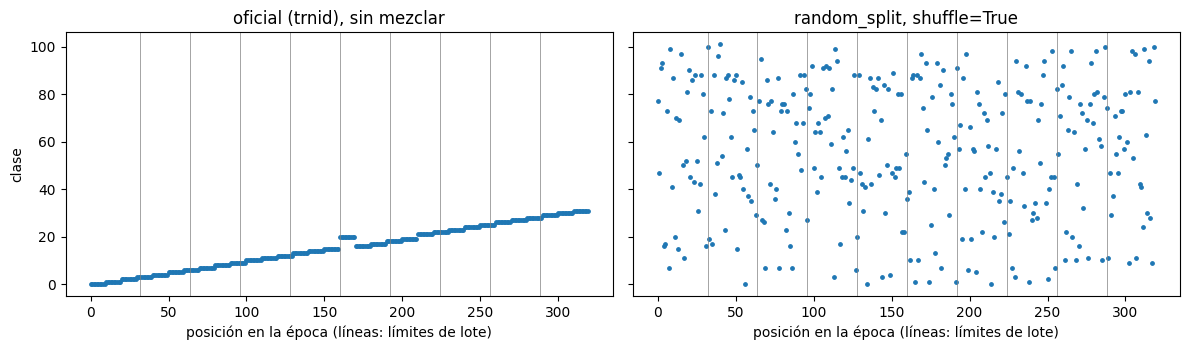

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for eje, nombre in zip(ejes, ["oficial (trnid), sin mezclar", "random_split, shuffle=True"]):
    datos, mezclar = casos[nombre]
    torch.manual_seed(0)
    lotes = [lote for _, lote in zip(range(10), DataLoader(datos, batch_size=32, shuffle=mezclar))]
    serie = torch.cat(lotes)
    eje.scatter(range(len(serie)), serie, s=6)
    for k in range(1, 10):
        eje.axvline(32 * k, color="gray", linewidth=0.5)
    eje.set_title(nombre)
    eje.set_xlabel("posición en la época (líneas: límites de lote)")
ejes[0].set_ylabel("clase")
plt.tight_layout()
plt.show()

Los primeros diez lotes de cada caso. Sin mezclar, la división oficial avanza por las clases en escalera: el modelo vería una clase tras otra, nunca juntas. La escalera sigue el número de clase, 0, 1, 2..., salvo un tramo: `setid.mat` pone las 10 fotos de la clase 20 entre las de la 15 y la 16, y ese es el salto que se ve en la posición 160. Mezclando, cada lote cubre todo el rango.

La regla del curso: **`shuffle=True` en el entrenamiento** y **`shuffle=False` en la validación y la prueba**. En la evaluación no se aprende nada, el orden no cambia el resultado, y sin mezclar los lotes son siempre los mismos, lo que facilita comparar.

## 11. Lotes y épocas

Ya podemos armar los tres `DataLoader`, con los subconjuntos de la forma 1 de la sección 7:

In [23]:
TAMANO_LOTE = 32
cargador_entrenamiento = DataLoader(entrenamiento_1, batch_size=TAMANO_LOTE, shuffle=True)
cargador_validacion = DataLoader(validacion_1, batch_size=TAMANO_LOTE, shuffle=False)
cargador_prueba = DataLoader(prueba_1, batch_size=TAMANO_LOTE, shuffle=False)

for nombre, cargador in [("entrenamiento", cargador_entrenamiento), ("validación", cargador_validacion),
                         ("prueba", cargador_prueba)]:
    fotos = len(cargador.dataset)
    print(f"{nombre:13s}: {fotos:5d} fotos / {TAMANO_LOTE} = {fotos / TAMANO_LOTE:7.3f}  ->  {len(cargador):3d} lotes, "
          f"el último con {fotos - (len(cargador) - 1) * TAMANO_LOTE} fotos")

entrenamiento:  5732 fotos / 32 = 179.125  ->  180 lotes, el último con 4 fotos
validación   :  1228 fotos / 32 =  38.375  ->   39 lotes, el último con 12 fotos
prueba       :  1229 fotos / 32 =  38.406  ->   39 lotes, el último con 13 fotos


Una **época** es una pasada completa por el entrenamiento: 5.732 / 32 = 179.1, así que son 179 lotes completos y un lote 180 con las 4 fotos que sobran. En general hay ⌈N / B⌉ lotes y el último tiene las que quedan. Que salga más chico es normal: la pérdida de cada lote es un promedio, así que su escala no depende de cuántas fotos traiga.

Con `drop_last=True` ese último lote se descarta, como dice la documentación, cuando el tamaño del dataset no es divisible por el del lote. Esas 4 fotos no se pierden para siempre: como el entrenamiento se mezcla en cada época, las que quedan afuera cambian.

In [24]:
sin_ultimo = DataLoader(entrenamiento_1, batch_size=TAMANO_LOTE, shuffle=True, drop_last=True)
print("con drop_last=True:", len(sin_ultimo), "lotes;", len(sin_ultimo) * TAMANO_LOTE, "fotos por época de", len(entrenamiento_1))

con drop_last=True: 179 lotes; 5728 fotos por época de 5732


Para mirar un lote sin escribir un bucle, `next(iter(cargador))`: `iter` empieza una época nueva y `next` saca su primer lote. Cada llamada empieza otra época, así que con `shuffle=True` cada vez sale un lote distinto, y cada vez se cargan 32 fotos.

imágenes : (32, 3, 224, 224) torch.float32
etiquetas: (32,) torch.int64 [26, 72, 50, 39, 76, 40, 55, 92]


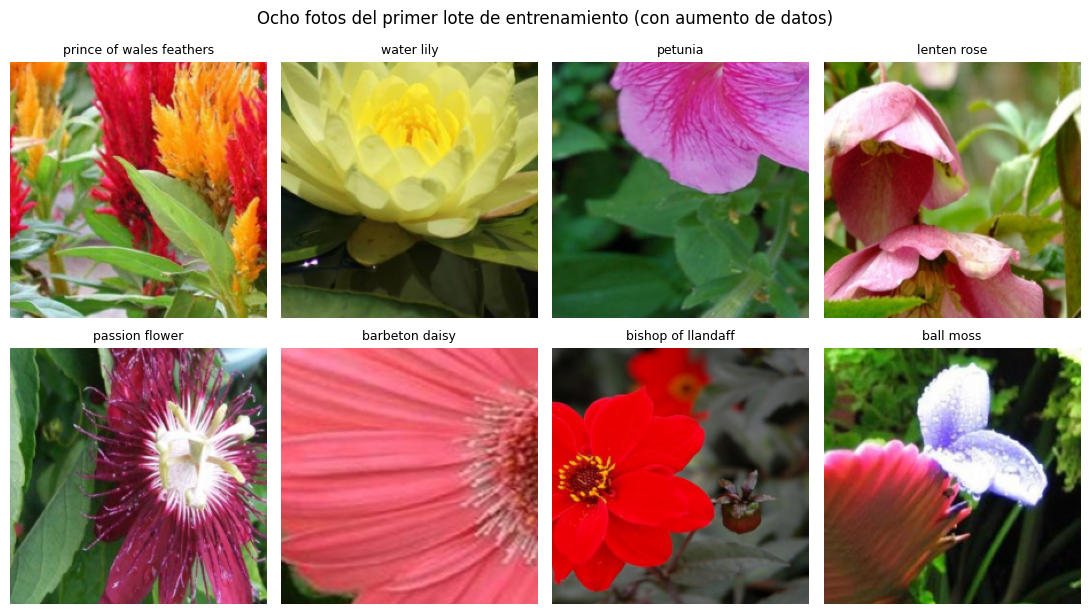

In [25]:
imagenes, etiquetas_lote = next(iter(cargador_entrenamiento))
print("imágenes :", tuple(imagenes.shape), imagenes.dtype)
print("etiquetas:", tuple(etiquetas_lote.shape), etiquetas_lote.dtype, etiquetas_lote[:8].tolist())

fig, ejes = plt.subplots(2, 4, figsize=(11, 6.4))
for eje, x, y in zip(ejes.flat, imagenes, etiquetas_lote):
    eje.imshow(para_mostrar(x))
    eje.set_title(NOMBRES[y], fontsize=9)
    eje.axis("off")
plt.suptitle("Ocho fotos del primer lote de entrenamiento (con aumento de datos)")
plt.tight_layout()
plt.show()

Las formas son las que espera un modelo de imágenes: `[32, 3, 224, 224]`, es decir **[lote, canales, alto, ancho]**, y `[32]` etiquetas `int64`, una por foto. El `DataLoader` apiló 32 tensores `[3, 224, 224]` agregando una dimensión al frente, como en el módulo 2 (`00-datos/01_transforms_dataset_y_dataloader`, sección 8). Para eso las 32 fotos tienen que medir lo mismo, que es justo lo que garantiza el recorte a 224.

Mirar un lote así, antes de entrenar, es la comprobación más barata que hay: confirma las formas y los tipos, que las etiquetas tienen sentido y que el aumento de datos produce flores reconocibles.

## 12. Cuánto tarda una época

MNIST cabía en memoria y entregar una época tomaba segundos. Aquí cada foto se lee del disco, se decodifica de JPEG y se transforma. Medimos 5 lotes de validación y extrapolamos a una época de entrenamiento. Es una aproximación: el entrenamiento usa otro transform, con recortes al azar en vez de `Resize` y recorte central, pero los dos parten de abrir y decodificar la misma clase de foto.

In [26]:
def segundos_por_lote(cargador, lotes=5):
    inicio = time.perf_counter()
    for i, _ in enumerate(cargador):
        if i + 1 == lotes:
            break
    return (time.perf_counter() - inicio) / lotes


por_lote = segundos_por_lote(DataLoader(validacion_1, batch_size=TAMANO_LOTE))
print(f"{por_lote:.2f} s por lote de {TAMANO_LOTE}  ->  {1000 * por_lote / TAMANO_LOTE:.0f} ms por foto")
print(f"una época de entrenamiento ({len(cargador_entrenamiento)} lotes): unos {por_lote * len(cargador_entrenamiento):.0f} s "
      f"solo en cargar, sin contar el modelo")

0.72 s por lote de 32  ->  22 ms por foto
una época de entrenamiento (180 lotes): unos 129 s solo en cargar, sin contar el modelo


¿En qué se va ese tiempo? Separamos los pasos para 50 fotos:

In [27]:
rutas = [os.path.join(CARPETA, "jpg", f"image_{i + 1:05d}.jpg") for i in validacion.indices[:50]]
tiempos = {"abrir y decodificar el JPEG": 0.0, "Resize(256)": 0.0, "CenterCrop + ToTensor + Normalize": 0.0}
resto = transforms.Compose(transform_evaluacion.transforms[1:])

for ruta in rutas:
    t0 = time.perf_counter()
    with Image.open(ruta) as archivo:
        foto = archivo.convert("RGB")
    t1 = time.perf_counter()
    reducida = transforms.Resize(256)(foto)
    t2 = time.perf_counter()
    resto(reducida)
    t3 = time.perf_counter()
    tiempos["abrir y decodificar el JPEG"] += t1 - t0
    tiempos["Resize(256)"] += t2 - t1
    tiempos["CenterCrop + ToTensor + Normalize"] += t3 - t2

total = sum(tiempos.values())
for paso, t in tiempos.items():
    print(f"{paso:35s} {1000 * t / len(rutas):5.1f} ms por foto   ({t / total:4.0%})")
print(f"tamaño de las fotos originales: {foto.size}")

abrir y decodificar el JPEG           5.5 ms por foto   ( 24%)
Resize(256)                           6.0 ms por foto   ( 26%)
CenterCrop + ToTensor + Normalize    11.8 ms por foto   ( 51%)
tamaño de las fotos originales: (667, 500)


La última foto medida tiene 667 × 500 píxeles (ancho × alto): el artículo de Nilsback y Zisserman dice que las fotos se reescalaron para que el lado más corto mida 500 (sección 4). Los números exactos dependen del computador y de qué más esté haciendo, pero ningún paso es despreciable: cada uno cuesta milisegundos y se repite para cada foto en cada época. Los dos primeros dependen además del tamaño de la foto original: decodificar y reducir una foto de 667 × 500 cuesta más que hacerlo con una más chica. En total son más de diez milisegundos por foto, y uno o varios minutos por época solo en cargar.

Hay tres salidas, de menos a más trabajo:

- **`num_workers`**: el `DataLoader` lanza varios procesos que preparan los lotes siguientes mientras el modelo entrena con el actual. Como en el módulo 2, se prueba en un script `.py`, porque en Windows los procesos auxiliares a veces no arrancan desde un notebook (ejercicio 5).
- **Reducir una sola vez**: guardar una copia de las fotos con el lado corto en 256 ahorra en cada época decodificar una foto grande y reducirla (ejercicio 6).
- **Precargar en memoria**, como hicimos con MNIST, si cabe. Hay dos versiones. Guardar las fotos **ya transformadas** solo sirve sin transformaciones aleatorias, como en la validación y la prueba. Con aumento de datos se guardan las fotos **decodificadas y reducidas**, como enteros de 8 bits, y el aumento se aplica sobre esos tensores en cada época. ¿Cuánto ocupa cada versión para el entrenamiento? Para la segunda leemos solo la cabecera de cada JPEG, que trae su tamaño, sin decodificar la foto:

In [28]:
por_foto = 3 * 224 * 224
print(f"entrenamiento ya transformado, en float32  : {len(entrenamiento) * por_foto * 4 / 1e9:.2f} GB")
print(f"lo mismo, como enteros de 8 bits           : {len(entrenamiento) * por_foto / 1e9:.2f} GB")

pixeles_reducidos = 0
for i in entrenamiento.indices:
    with Image.open(os.path.join(CARPETA, "jpg", f"image_{i + 1:05d}.jpg")) as archivo:   # lee solo la cabecera
        ancho, alto = archivo.size
    escala = 256 / min(ancho, alto)
    pixeles_reducidos += round(ancho * escala) * round(alto * escala)
print(f"fotos reducidas a lado corto 256, 8 bits   : {3 * pixeles_reducidos / 1e9:.2f} GB")

entrenamiento ya transformado, en float32  : 3.45 GB
lo mismo, como enteros de 8 bits           : 0.86 GB


fotos reducidas a lado corto 256, 8 bits   : 1.50 GB


3.45 GB en `float32` es mucho para un computador común. Las fotos reducidas a 256 y guardadas en 8 bits ocupan bastante menos y conservan algo de margen alrededor del recorte de 224, que es lo que necesita `RandomResizedCrop`. Si caben, cargar una época deja de costar minutos. Si no caben, como pasa con datasets más grandes, se carga a pedido y lo que se optimiza es cómo se carga.

## 13. Un CSV leído en cada `__getitem__`

Muchos datasets traen las etiquetas en un archivo CSV en vez de un `.mat`. El error que señala el curso es leerlo dentro de `__getitem__`: el archivo completo se vuelve a leer por cada foto. Escribimos un CSV con el nombre de cada archivo y su etiqueta, en una carpeta propia:

In [29]:
carpeta_csv = os.path.join(RAIZ, "flores_csv")
os.makedirs(carpeta_csv, exist_ok=True)
ruta_csv = os.path.join(carpeta_csv, "etiquetas.csv")

with open(ruta_csv, "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.writer(archivo)
    escritor.writerow(["archivo", "etiqueta"])
    for i, etiqueta in enumerate(flores.etiquetas):
        escritor.writerow([f"image_{i + 1:05d}.jpg", etiqueta])

print(f"{os.path.getsize(ruta_csv) / 1000:.0f} KB, {len(flores) + 1} líneas")
with open(ruta_csv, encoding="utf-8") as archivo:
    print("".join(archivo.readlines()[:3]))

163 KB, 8190 líneas
archivo,etiqueta
image_00001.jpg,76
image_00002.jpg,76



Dos datasets que devuelven lo mismo, el nombre del archivo y la etiqueta. Para medir solo el costo del CSV, ninguno abre la foto:

In [30]:
class CSVReleido(Dataset):
    """Mal: lee el CSV completo cada vez que se pide una muestra."""

    def __init__(self, ruta):
        self.ruta = ruta

    def __len__(self):
        return len(flores)

    def __getitem__(self, idx):
        with open(self.ruta, encoding="utf-8") as archivo:
            filas = list(csv.reader(archivo))[1:]
        nombre, etiqueta = filas[idx]
        return nombre, int(etiqueta)


class CSVUnaVez(Dataset):
    """Bien: lee el CSV una vez, en __init__."""

    def __init__(self, ruta):
        with open(ruta, encoding="utf-8") as archivo:
            self.filas = list(csv.reader(archivo))[1:]

    def __len__(self):
        return len(self.filas)

    def __getitem__(self, idx):
        nombre, etiqueta = self.filas[idx]
        return nombre, int(etiqueta)


releido, una_vez = CSVReleido(ruta_csv), CSVUnaVez(ruta_csv)
print("¿Devuelven lo mismo?", all(releido[i] == una_vez[i] for i in range(0, len(flores), 997)))

lecturas = 10 * len(entrenamiento)          # 10 épocas de entrenamiento
for nombre, datos in [("releído en cada __getitem__", releido), ("leído una vez en __init__", una_vez)]:
    inicio = time.perf_counter()
    for i in range(200):
        datos[(i * 37) % len(datos)]
    por_muestra = (time.perf_counter() - inicio) / 200
    print(f"{nombre:28s}: {1000 * por_muestra:8.4f} ms por muestra  ->  {lecturas} muestras (10 épocas): "
          f"{por_muestra * lecturas:6.1f} s")

¿Devuelven lo mismo? True


releído en cada __getitem__ :  24.4666 ms por muestra  ->  57320 muestras (10 épocas): 1402.4 s
leído una vez en __init__   :   0.0019 ms por muestra  ->  57320 muestras (10 épocas):    0.1 s


Diez épocas son 57.320 muestras. Releer el CSV cuesta milisegundos por muestra, del mismo orden que cargar la propia foto (sección 12), y en diez épocas suma del orden de un cuarto de hora de trabajo inútil. Leerlo una vez cuesta una fracción de segundo en total. Y este CSV es chico, de 8.189 líneas: el costo crece con el tamaño del archivo, así que con un millón de fotos el mismo error haría inviable el entrenamiento.

La regla es la de carga perezosa de `00-acceso/01_un_dataset_propio`, vista desde el otro lado: en `__init__` va todo lo liviano que se usa siempre (rutas, etiquetas, el CSV), y en `__getitem__` solo lo pesado que depende de la muestra (abrir esa foto).

## 14. Memoria y tamaño del lote

En una GPU, uno de los errores más comunes al empezar es `torch.OutOfMemoryError: CUDA out of memory`. Aquí no hay GPU para reproducirlo, pero se puede entender con cuentas. Un lote de entrada ocupa 4 bytes por número:

In [31]:
for lote in [16, 32, 64, 128, 256]:
    print(f"lote de {lote:3d}: entrada [{lote}, 3, 224, 224] en float32 = {lote * por_foto * 4 / 1e6:6.0f} MB")

lote de  16: entrada [16, 3, 224, 224] en float32 =     10 MB
lote de  32: entrada [32, 3, 224, 224] en float32 =     19 MB
lote de  64: entrada [64, 3, 224, 224] en float32 =     39 MB
lote de 128: entrada [128, 3, 224, 224] en float32 =     77 MB
lote de 256: entrada [256, 3, 224, 224] en float32 =    154 MB


La entrada no es lo que llena la memoria. En el módulo 2 medimos lo que autograd retiene para `backward()` y vimos que crece en proporción al lote (`03-dispositivos/01_cpu_gpu_y_dispositivos`, sección 7). Con fotos es mucho peor, porque las capas producen mapas del tamaño de la imagen. Lo medimos con una sola capa convolucional seguida de una ReLU: las convoluciones se estudian en el módulo 4, y aquí solo importa que esta capa convierte cada foto en 64 mapas de 224 × 224.

In [32]:
def memoria_retenida(modelo, entrada):
    """Bytes que autograd guarda para backward(), sin contar los pesos (como en el módulo 2)."""
    pesos = {p.data_ptr() for p in modelo.parameters()}
    retenidos = {}

    def anotar(tensor):
        if tensor.data_ptr() not in pesos:
            retenidos[tensor.data_ptr()] = tensor.numel() * tensor.element_size()
        return tensor

    with torch.autograd.graph.saved_tensors_hooks(anotar, lambda tensor: tensor):
        modelo(entrada)
    return sum(retenidos.values())


una_capa = nn.Sequential(nn.Conv2d(3, 64, kernel_size=3, padding=1), nn.ReLU())
for lote in [4, 8, 16]:
    retenido = memoria_retenida(una_capa, torch.randn(lote, 3, 224, 224))
    print(f"lote de {lote:2d}: entrada {lote * por_foto * 4 / 1e6:5.1f} MB   retenido para backward {retenido / 1e6:6.1f} MB")

por_foto_retenido = retenido / 16
print(f"\npor foto: {por_foto_retenido / 1e6:.1f} MB  ->  con lotes de 32: {32 * por_foto_retenido / 1e9:.2f} GB, "
      f"con lotes de 256: {256 * por_foto_retenido / 1e9:.1f} GB")

lote de  4: entrada   2.4 MB   retenido para backward   53.8 MB


lote de  8: entrada   4.8 MB   retenido para backward  107.6 MB


lote de 16: entrada   9.6 MB   retenido para backward  215.2 MB

por foto: 13.4 MB  ->  con lotes de 32: 0.43 GB, con lotes de 256: 3.4 GB


Una sola capa retiene unos 13 MB por foto, más de veinte veces lo que ocupa la foto de entrada, y crece exactamente en proporción al lote. Un modelo real tiene decenas de capas. Con lotes de 256, esta capa sola ya necesitaría 3.4 GB, casi la mitad de una GPU de 8 GB.

Qué hacer ante `CUDA out of memory`, en orden:

1. **Bajar el tamaño del lote**, como recomienda el curso: a 32 o 16, y después ir subiendo mientras quepa. La memoria retenida baja en la misma proporción.
2. Si hace falta un lote efectivo más grande, **acumular gradientes** de varios lotes chicos antes de cada `step()` (módulo 2, `02-entrenamiento/02_gradientes_y_optimizadores`, sección 7).
3. Reducir el tamaño de las imágenes o del modelo.

El tamaño del lote no cambia la memoria de los pesos, los gradientes ni el estado del optimizador, que es fija (la tabla de la sección 7 de `03-dispositivos/01_cpu_gpu_y_dispositivos`, en el módulo 2).

## 15. Resumen

- **Entrenamiento** para aprender, **validación** para decidir y **prueba** para informar una sola vez. Mirar la prueba para decidir filtra información y la cifra final deja de medir datos nuevos.
- `random_split(dataset, [n_e, n_v, n_p], generator=...)`: con enteros, la prueba se calcula como el resto para que la suma dé exacto. Con fracciones, `random_split` reparte el resto por turnos y los tamaños pueden diferir en uno. La división se fija con una semilla y se guarda.
- Los subconjuntos son **vistas**: un `Subset` guarda el dataset de abajo y una lista de índices. No copia nada y los tres comparten el dataset.
- Por eso comparten el transform. Asignárselo al `Subset` no hace nada, y cambiárselo al dataset de abajo se lo cambia a los tres: el aumento de datos se cuela en la validación sin aviso. Se arregla con un envoltorio por subconjunto o con un dataset de base por transform.
- `random_split` sortea fotos, no clases. Con clases chicas, una clase puede quedar con 1 foto en la prueba. **Estratificar** (dividir cada clase por separado) deja todas cerca del 15%.
- La división oficial de Oxford (10 + 10 por clase, el resto para prueba) sirve para comparar con resultados publicados, que además miden la exactitud promediada por clase; la de 70/15/15, para entrenar con más datos.
- Los archivos y la división oficial vienen **agrupados por clase**. `random_split` mezcla una vez; `shuffle=True` mezcla en cada época. Entrenamiento con `shuffle=True`, validación y prueba sin.
- Hay ⌈N / B⌉ lotes por época y el último puede ser más chico; `drop_last=True` lo descarta. `next(iter(cargador))` muestra un lote: `[32, 3, 224, 224]` y `[32]`.
- Cargar una foto toma más de diez milisegundos (decodificar, reducir, convertir y normalizar), y se repite en cada época. Lo liviano va en `__init__` y lo pesado en `__getitem__`: releer un CSV por muestra multiplica el costo.
- Lo que llena la memoria son las activaciones, que crecen en proporción al lote. Ante `CUDA out of memory`, lo primero es bajar `batch_size`.

## Ejercicios

1. Antes de ejecutar: con `batch_size=64`, ¿cuántos lotes tienen el entrenamiento, la validación y la prueba de la sección 4, y cuántas fotos trae el último de cada uno? ¿Y con la división de fracciones? Compruébalo.
2. Repite la sección 8 con las semillas 1 a 10 de `random_split`. ¿Cuántas fotos tiene en la prueba la clase peor representada en cada caso? ¿Hubo alguna semilla con una clase ausente de la validación?
3. Si tienes scikit-learn, arma una división 70/15/15 estratificada con dos llamadas a `sklearn.model_selection.train_test_split(..., stratify=...)` y compárala con `division_estratificada`: ¿qué fracción de cada clase queda en cada conjunto?
4. Guarda los índices de la sección 4 en un archivo JSON dentro de `modulo-3/data` y escribe una función que, a partir de ese archivo, reconstruya los tres subconjuntos con la forma 2 de la sección 7. Comprueba en una sesión nueva de Python que salen los mismos índices.
5. En un script `.py`, mide cuánto tarda una época de validación de las flores con `num_workers=0` y `4`, y haz lo mismo con el pipeline de MNIST del módulo 2 (`ToTensor` y `Normalize`, lotes de 64). ¿En cuál ayudan más los procesos auxiliares? Explica la diferencia a partir de cuánto trabajo cuesta preparar cada muestra y de que cada lote preparado por un proceso auxiliar hay que pasárselo al proceso principal. (En Windows, el código que crea el `DataLoader` tiene que ir dentro de `if __name__ == "__main__":`.)
6. Guarda una copia de las 8.189 fotos con el lado corto reducido a 256 en una carpeta nueva de `modulo-3/data` y repite la medición de la sección 12 sobre ella. ¿Cuánto baja el tiempo por foto? ¿Se puede usar la misma copia para el entrenamiento con `RandomResizedCrop`? ¿Qué se pierde?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **scikit-learn**, [*Cross-validation: evaluating estimator performance*](https://scikit-learn.org/stable/modules/cross_validation.html) (guía de usuario, sección 3.1):
  - Introducción: "Learning the parameters of a prediction function and testing it on the same data is a methodological mistake: a model that would just repeat the labels of the samples that it has just seen would have a perfect score but would fail to predict anything useful on yet-unseen data."
  - Introducción: "This way, knowledge about the test set can “leak” into the model and evaluation metrics no longer report on generalization performance. To solve this problem, yet another part of the dataset can be held out as a so-called “validation set”" y "by partitioning the available data into three sets, we drastically reduce the number of samples which can be used for learning the model, and the results can depend on a particular random choice for the pair of (train, validation) sets."
  - Sección 3.1.2.2, [*Cross-validation iterators with stratification based on class labels*](https://scikit-learn.org/stable/modules/cross_validation.html#stratification): "cross-validation splitting can generate train or validation folds without any occurrence of a particular class" y "splitters such as StratifiedKFold and StratifiedShuffleSplit implement stratified sampling to ensure that relative class frequencies are approximately preserved in each fold."
- **Oxford Flowers 102**, [página del Visual Geometry Group](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/): "Each class consists of between 40 and 258 images." Su [README](https://thor.robots.ox.ac.uk/flowers/102/README.txt), sección *Datasplit*: "The datasplits used in this paper are specified in setid.mat", "The results in the paper are produced on a 103 category database. The two categories labeled Petunia have since been merged since they are the same." y "There is a training file (trnid), a validation file (valid) and a testfile (tstid)."
- M.-E. Nilsback y A. Zisserman (2008), [*Automated flower classification over a large number of classes*](https://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/nilsback08.pdf), ICVGIP. Sección 4: "The images are rescaled so that the smallest dimension is 500 pixels.", "The training set and validation set each consist of 10 images per class (totalling 1030 images each). The test set consist of the remaining 6129 images (minimum 20 per class). The validation set is used to optimize the number of visual words for each of the features, and the radius and spacing of the SIFT features." y "the final performance is the classification averaged over all classes (not over all images)." Sección 4.1: "Once the parameters have been determined on the validation set, the classifiers are retrained using all the available training data (both the training and validation sets)."

**Documentación de PyTorch y torchvision**

- [`torch.utils.data.random_split`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.random_split): "Randomly split a dataset into non-overlapping new datasets of given lengths.", "If a list of fractions that sum up to 1 is given, the lengths will be computed automatically as floor(frac * len(dataset)) for each fraction provided." y "After computing the lengths, if there are any remainders, 1 count will be distributed in round-robin fashion to the lengths until there are no remainders left."
- [`torch.utils.data.Subset`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.Subset): "Subset of a dataset at specified indices." y la nota "When subclassing `Subset` and overriding `__getitem__`, you **must** also override `__getitems__` to ensure `DataLoader` works correctly with your custom logic. If you override only `__getitem__`, a `NotImplementedError` will be raised when using `DataLoader`." En PyTorch 2.11 la comprobación está en `Subset.__init__`, y por eso el error sale al crear el objeto (lo comprobamos en la sección 7).
- [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader), parámetros: `batch_size`, "how many samples per batch to load (default: 1)"; `shuffle`, "set to True to have the data reshuffled at every epoch (default: False)"; `drop_last`, "set to True to drop the last incomplete batch, if the dataset size is not divisible by the batch size. If False and the size of dataset is not divisible by the batch size, then the last batch will be smaller."
- [`torchvision.models.resnet18`](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html), pesos `IMAGENET1K_V1`: "The images are resized to resize_size=[256] using interpolation=InterpolationMode.BILINEAR, followed by a central crop of crop_size=[224]. Finally the values are first rescaled to [0.0, 1.0] and then normalized using mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]."

**Lo que no viene de una fuente** son los números de este notebook (tamaños de cada conjunto, fotos por clase, clases por lote, tiempos y memoria): todos salen de las celdas de código. También son nuestros los dos intentos fallidos de la sección 6, las dos formas de la sección 7 y la división estratificada a mano. Lo que dice el curso (70/15/15, `shuffle` solo en entrenamiento, el CSV en `__getitem__`, bajar el lote ante `CUDA out of memory`) viene de su video *DataLoader*.